In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import dask
from dask.diagnostics import ProgressBar

import warnings
warnings.filterwarnings('ignore')

import geopandas as gpd
import regionmask
import xgcm
import regionate
import matplotlib.pyplot as plt
from shapely.geometry import box

import cmocean.cm as cm

import pandas as pd

In [2]:
nwa_data = "/dfs9/hfdrake_hpc/datasets/NWA/NWA12_COBALT_2025_04_bugfixes/gfdl.ncrc6-intel23-prod-hdf5/pp/"
data = "/pub/mariant3/NWA/data/"

In [3]:
static = f"{nwa_data}ocean_threeday/ocean_monthly_z/ocean_threeday.static.nc"
shp_path = f"{data}longhurst_v4_2010/Longhurst_world_v4_2010.shp"

In [4]:
temp_ds = xr.open_mfdataset(f"{nwa_data}ocean_monthly_z/ts/monthly/5yr/*.thetao.nc",
                            chunks={"time": 12}, parallel=False)

no3 = xr.open_mfdataset(f"{nwa_data}ocean_cobalt_tracers_month_z/ts/monthly/5yr/ocean_cobalt_tracers_month_z.*no3.nc",
                        chunks={"time": 12}, parallel=False)

tos_clim   = xr.open_dataset(f"{data}tos_monthly_clim_1993-2022.nc")
no3s_clim  = xr.open_dataset(f"{data}no3s_monthly_clim_1993-2022.nc")
tos_per90  = xr.open_dataset(f"{data}tos_monthly_per90_1993-2022.nc")
no3s_per10 = xr.open_dataset(f"{data}no3s_monthly_per10_1993-2022.nc")

tos_clim

<xarray.Dataset>
Dimensions:  (xh: 775, yh: 845, time: 360)
Coordinates:
  * xh       (xh) float64 -98.0 -97.92 -97.84 -97.76 ... -36.24 -36.16 -36.08
  * yh       (yh) float64 5.273 5.352 5.432 5.511 ... 51.88 51.9 51.91 51.93
    month    (time) int64 ...
  * time     (time) datetime64[ns] 1993-01-16T12:00:00 ... 2022-12-16T12:00:00
Data variables:
    thetao   (time, yh, xh) float32 ...

In [5]:
tos      = tos_clim["thetao"] 
no3s     = no3s_clim["no3"]
tos_p90  = tos_per90["thetao"]
no3s_p10 = no3s_per10["no3"]
tos

<xarray.DataArray 'thetao' (time: 360, yh: 845, xh: 775)>
[235755000 values with dtype=float32]
Coordinates:
  * xh       (xh) float64 -98.0 -97.92 -97.84 -97.76 ... -36.24 -36.16 -36.08
  * yh       (yh) float64 5.273 5.352 5.432 5.511 ... 51.88 51.9 51.91 51.93
    month    (time) int64 ...
  * time     (time) datetime64[ns] 1993-01-16T12:00:00 ... 2022-12-16T12:00:00
Attributes:
    units:          degC
    long_name:      Sea Water Potential Temperature
    cell_methods:   area:mean z_l:mean yh:mean xh:mean time: mean
    cell_measures:  volume: volcello area: areacello
    time_avg_info:  average_T1,average_T2,average_DT
    standard_name:  sea_water_potential_temperature

In [6]:
xh, yh = tos.xh, tos.yh

lon, lat = xr.broadcast(xh, yh)
lon, lat = lon.transpose("yh", "xh"), lat.transpose("yh", "xh")

def edges(c):
    c = c.values
    mid = (c[1:] + c[:-1]) / 2
    return np.concatenate([[c[0] - (mid[0] - c[0])], mid, [c[-1] + (c[-1] - mid[-1])]])

xq, yq = edges(xh), edges(yh)

ocean = tos.isel(time=0, drop=True).notnull()   

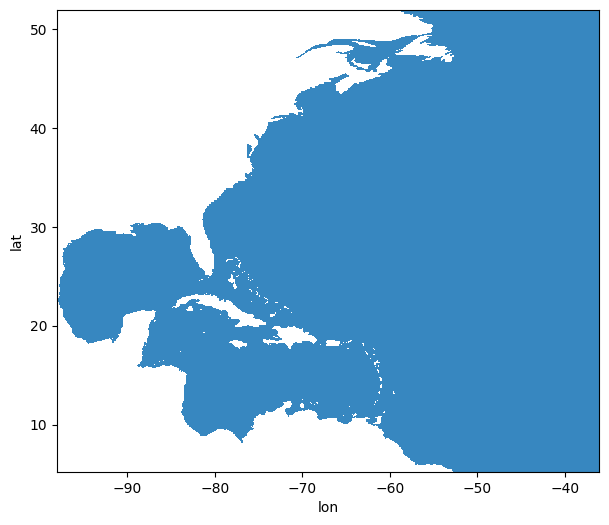

In [33]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.pcolormesh(xq, yq, ocean.where(ocean), cmap="Blues", vmin=0, vmax=1.5)
ax.set_xlabel("lon"); ax.set_ylabel("lat");

In [8]:
longhurst = gpd.read_file(shp_path)
longhurst[["ProvCode", "ProvDescr"]]

,ProvCode,ProvDescr
0,BPLR,Polar - Boreal Polar Province (POLR)
1,ARCT,Polar - Atlantic Arctic Province
2,SARC,Polar - Atlantic Subarctic Province
3,NADR,Westerlies - N. Atlantic Drift Province (WWDR)
4,GFST,Westerlies - Gulf Stream Province
5,NASW,Westerlies - N. Atlantic Subtropical Gyral Pro...
6,NATR,Trades - N. Atlantic Tropical Gyral Province (...
7,WTRA,Trades - Western Tropical Atlantic Province
8,ETRA,Trades - Eastern Tropical Atlantic Province
9,SATL,Trades - South Atlantic Gyral Province (SATG)


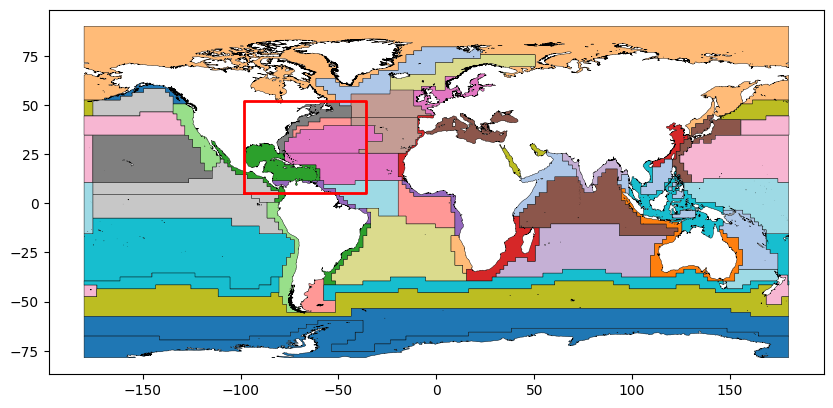

In [34]:
west, east, south, north = xq[0], xq[-1], yq[0], yq[-1]

ax = longhurst.plot(column="ProvCode", cmap="tab20", edgecolor="k", lw=0.3, figsize=(10, 5))
ax.plot([west, east, east, west, west], [south, south, north, north, south], "r", lw=2)

In [11]:
nwa_box = box(west, south, east, north)
provinces = longhurst.clip(nwa_box)
provinces = provinces[~provinces.geometry.is_empty]
provinces = provinces.dissolve(by="ProvCode", as_index=False)

provinces[["ProvCode", "ProvDescr"]]

,ProvCode,ProvDescr
0,ARCT,Polar - Atlantic Arctic Province
1,BPLR,Polar - Boreal Polar Province (POLR)
2,CAMR,Coastal - Central American Coastal Province
3,CARB,Trades - Caribbean Province
4,GFST,Westerlies - Gulf Stream Province
5,GUIA,Coastal - Guianas Coastal Province
6,NADR,Westerlies - N. Atlantic Drift Province (WWDR)
7,NASE,Westerlies - N. Atlantic Subtropical Gyral Pro...
8,NASW,Westerlies - N. Atlantic Subtropical Gyral Pro...
9,NATR,Trades - N. Atlantic Tropical Gyral Province (...


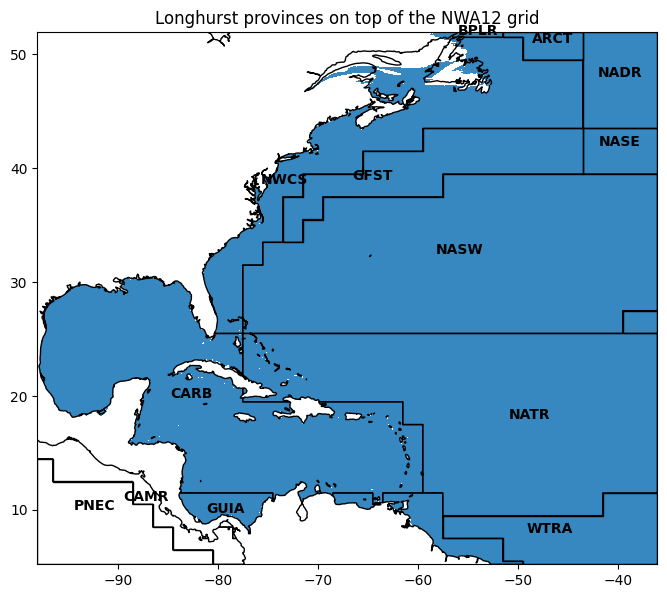

In [12]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.pcolormesh(xq, yq, ocean.where(ocean), cmap="Blues", vmin=0, vmax=1.5)
provinces.boundary.plot(ax=ax, color="k", lw=1)
for _, p in provinces.iterrows():
    pt = p.geometry.representative_point()
    ax.text(pt.x, pt.y, p.ProvCode, ha="center", weight="bold")
ax.set_xlim(west, east); ax.set_ylim(south, north)

(36.0, 46.0)

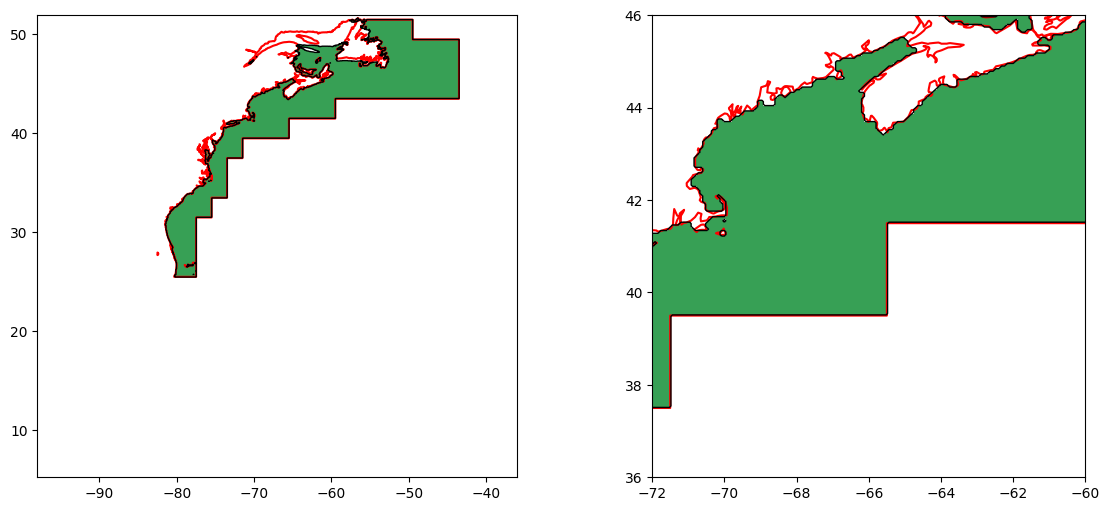

In [36]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
for ax in axs:
    ax.pcolormesh(xq, yq, mask_nwcs.where(mask_nwcs), cmap="Greens", vmin=0, vmax=1.5)
    one.boundary.plot(ax=ax, color="r", lw=1.5)
    ax.contour(lon, lat, mask_nwcs.astype(float), levels=[0.5], colors="k", linewidths=1)
axs[0].set_xlim(west, east); axs[0].set_ylim(south, north)

axs[1].set_xlim(-72, -60); axs[1].set_ylim(36, 46)


In [15]:
regions = regionmask.from_geopandas(provinces, names="ProvDescr", abbrevs="ProvCode", overlap=False)
masks = regions.mask_3D(lon, lat) & ocean
masks = masks.assign_coords(region=masks.abbrevs.values)

masks

<xarray.DataArray (region: 13, yh: 845, xh: 775)>
array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
...
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ...,  True,  True,  True],
        [False, False, False, ...,  True,  True,  True],
        [False, False, False, ...,  True,  True,  True],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]]])
Coordinates:
  * yh       (yh) float64 5.273 5.352 5.432 5.511 ... 51.88 51.9 51.91 51.93
  * xh       (xh) float64 -98.0 -97.92 -97.84 -97.76 ... -36.24 -36.16 -36.08
    abbrevs  (region) <U4 'ARCT' 'BPLR' 'CAMR' 'CARB' ... 'NWCS' 'PNEC' 'WTRA'
    names    (region) <U65 'Polar - Atlantic Arctic Province' ... 'Trades - W...
  * region   (region) <U4 'ARCT' 'BPLR' 'CAMR' 'CARB' ... 'NWCS' 'PNEC' 'WTRA'

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


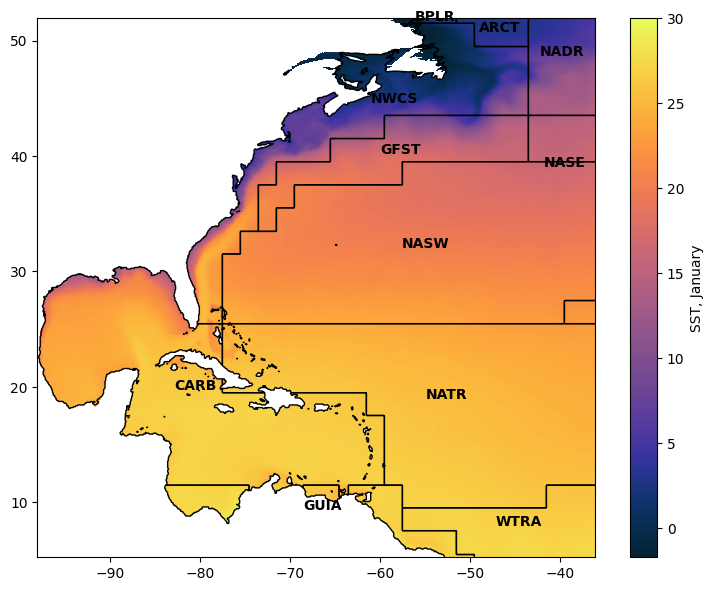

In [37]:
fig, ax = plt.subplots(figsize=(9, 7))
pc = ax.pcolormesh(xq, yq, tos.isel(time=0), cmap=cm.thermal)
fig.colorbar(pc, ax=ax, label="SST, January")
for code in masks.region.values:
    m = masks.sel(region=code)
    ax.contour(lon, lat, m.astype(float), levels=[0.5], colors="k", linewidths=1)
    ax.text(float(lon.where(m).mean()), float(lat.where(m).mean()), code, ha="center", weight="bold")

In [18]:
lon_c, lat_c = np.meshgrid(xq, yq)
ds_grid = xr.Dataset(
    coords={
        "xh": xh.values, "yh": yh.values, "xq": xq, "yq": yq,
        "geolon":   (("yh", "xh"), lon.values),
        "geolat":   (("yh", "xh"), lat.values),
        "geolon_c": (("yq", "xq"), lon_c),
        "geolat_c": (("yq", "xq"), lat_c),
    }
)
grid = xgcm.Grid(
    ds_grid,
    coords={"X": {"center": "xh", "outer": "xq"},
            "Y": {"center": "yh", "outer": "yq"}},
    boundary={"X": "extend", "Y": "extend"},
    autoparse_metadata=False,
)

number of pieces: 46


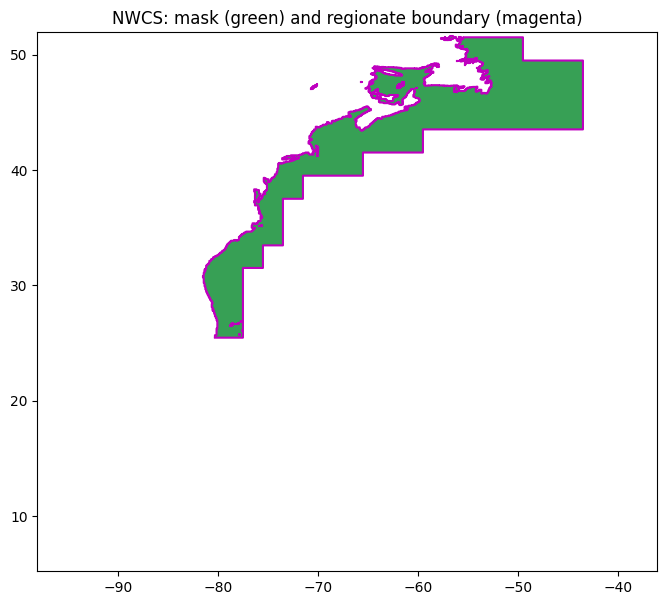

In [19]:
nwcs = regionate.MaskRegions(mask_nwcs, grid)

fig, ax = plt.subplots(figsize=(8, 7))
ax.pcolormesh(xq, yq, mask_nwcs.where(mask_nwcs), cmap="Greens", vmin=0, vmax=1.5)
for piece in nwcs.region_dict.values():
    ax.plot(piece.lons_c, piece.lats_c, "m-", lw=1.5)
ax.set_xlim(west, east); ax.set_ylim(south, north)

In [20]:
province_regions = {}
for code in masks.region.values:
    m = masks.sel(region=code).drop_vars(["abbrevs", "names", "region"])
    province_regions[str(code)] = regionate.MaskRegions(m, grid)

#### testing one region

In [22]:
# temp_nwcs       = temp_ds.thetao.isel(z_l=0).where(mask_nwcs).mean(["xh", "yh"]).compute()
# tos_clim_nwcs   = tos_clim.thetao.where(mask_nwcs).mean(["xh", "yh"]).compute()
# tos_per90_nwcs  = tos_per90.thetao.where(mask_nwcs).mean(["xh", "yh"]).compute()

# no3_nwcs        = no3.no3.isel(z_l=0).where(mask_nwcs).mean(["xh", "yh"]).compute()
# no3s_clim_nwcs  = no3s_clim.no3.where(mask_nwcs).mean(["xh", "yh"]).compute()
# no3s_per10_nwcs = no3s_per10.no3.where(mask_nwcs).mean(["xh", "yh"]).compute()

In [23]:
# temp_ds.thetao.isel(z_l=0,time=-1).where(mask_nwcs).plot()

In [24]:
# no3.no3.isel(z_l=0,time=-1).where(mask_nwcs).plot()

In [25]:
# fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# ax = axs[0]
# ax.plot(temp_nwcs.time, temp_nwcs, "k", lw=1, label="observed")
# ax.plot(tos_clim_nwcs.time, tos_clim_nwcs, color="grey", label="climatology")
# ax.plot(tos_per90_nwcs.time, tos_per90_nwcs, "r--", lw=1, label="90th percentile")
# ax.fill_between(temp_nwcs.time, tos_per90_nwcs, temp_nwcs,
#                 where=temp_nwcs > tos_per90_nwcs, color="r", alpha=0.4)
# ax.set_ylabel("surface temperature"); ax.legend(loc="upper left", fontsize=8); ax.set_title("NWCS")

# ax = axs[1]
# ax.plot(no3_nwcs.time, no3_nwcs, "k", lw=1, label="observed")
# ax.plot(no3s_clim_nwcs.time, no3s_clim_nwcs, color="grey", label="climatology")
# ax.plot(no3s_per10_nwcs.time, no3s_per10_nwcs, "--", color="darkorange", lw=1, label="10th percentile")
# ax.fill_between(no3_nwcs.time, no3s_per10_nwcs, no3_nwcs,
#                 where=no3_nwcs < no3s_per10_nwcs, color="darkorange", alpha=0.4)
# ax.set_ylabel("surface NO3"); ax.legend(loc="upper left", fontsize=8);

In [27]:
# save data for each mask
def province_loop(da):
    out = {}
    for region in masks.region.values:
        mask = masks.sel(region=region)
        out[str(region)] = da.where(mask).mean(["yh", "xh"]).compute()
    return xr.concat(list(out.values()), dim=pd.Index(list(out.keys()), name="region"))

prov = xr.Dataset({
    "temp_ds":    province_loop(temp_ds.thetao.isel(z_l=0)),
    "tos_clim":   province_loop(tos_clim.thetao),
    "tos_per90":  province_loop(tos_per90.thetao.drop_vars("quantile")),
    "no3":        province_loop(no3.no3.isel(z_l=0)),
    "no3s_clim":  province_loop(no3s_clim.no3),
    "no3s_per10": province_loop(no3s_per10.no3.drop_vars("quantile")),
})

In [28]:
prov.to_netcdf(f"{data}NWA_biogeochemical_provinces.nc")

In [31]:
xr.open_dataset(f"{data}NWA_biogeochemical_provinces.nc")

<xarray.Dataset>
Dimensions:     (time: 360, region: 13)
Coordinates:
  * time        (time) datetime64[ns] 1993-01-16T12:00:00 ... 2022-12-16T12:0...
    z_l         float64 ...
    abbrevs     (region) object ...
    names       (region) object ...
  * region      (region) object 'ARCT' 'BPLR' 'CAMR' ... 'NWCS' 'PNEC' 'WTRA'
    month       (time) int64 ...
Data variables:
    temp_ds     (region, time) float32 ...
    tos_clim    (region, time) float32 ...
    tos_per90   (region, time) float64 ...
    no3         (region, time) float32 ...
    no3s_clim   (region, time) float32 ...
    no3s_per10  (region, time) float64 ...

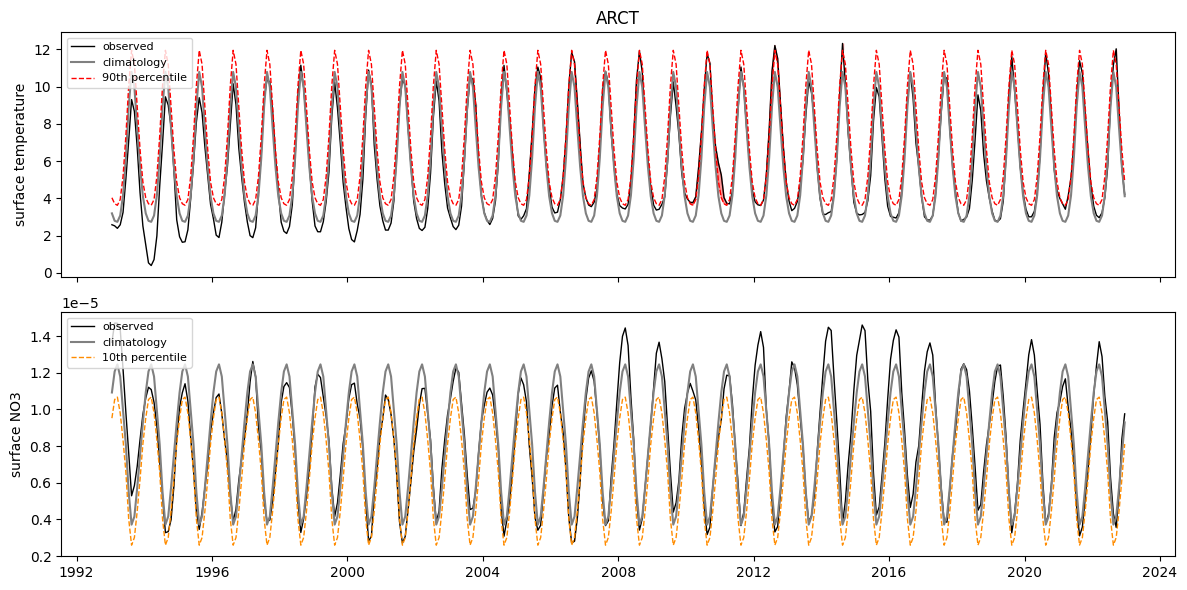

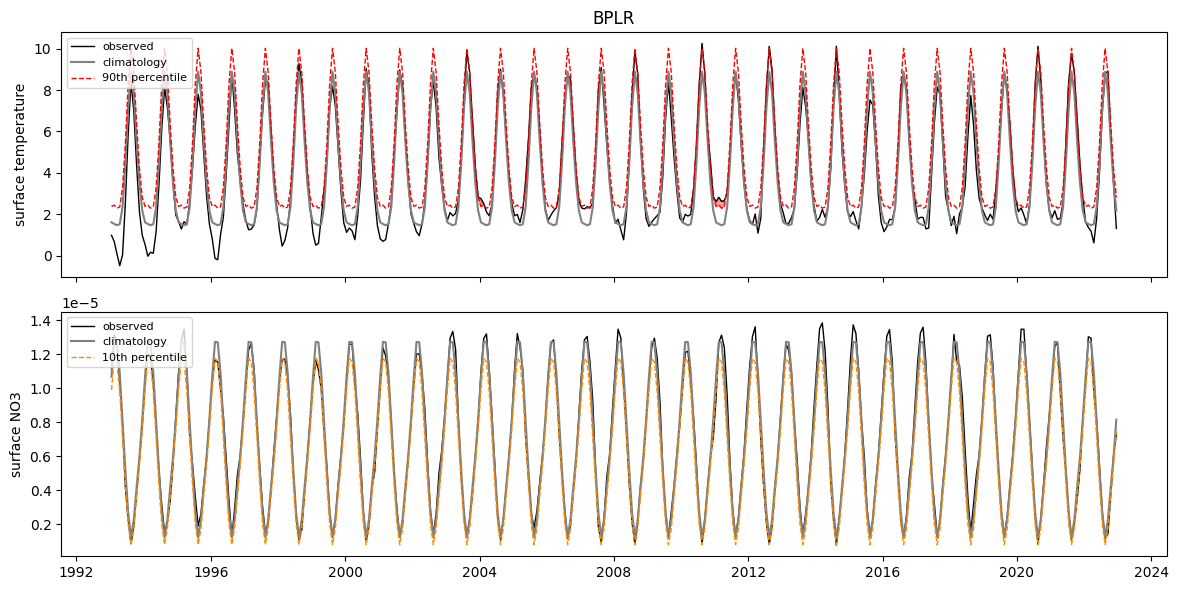

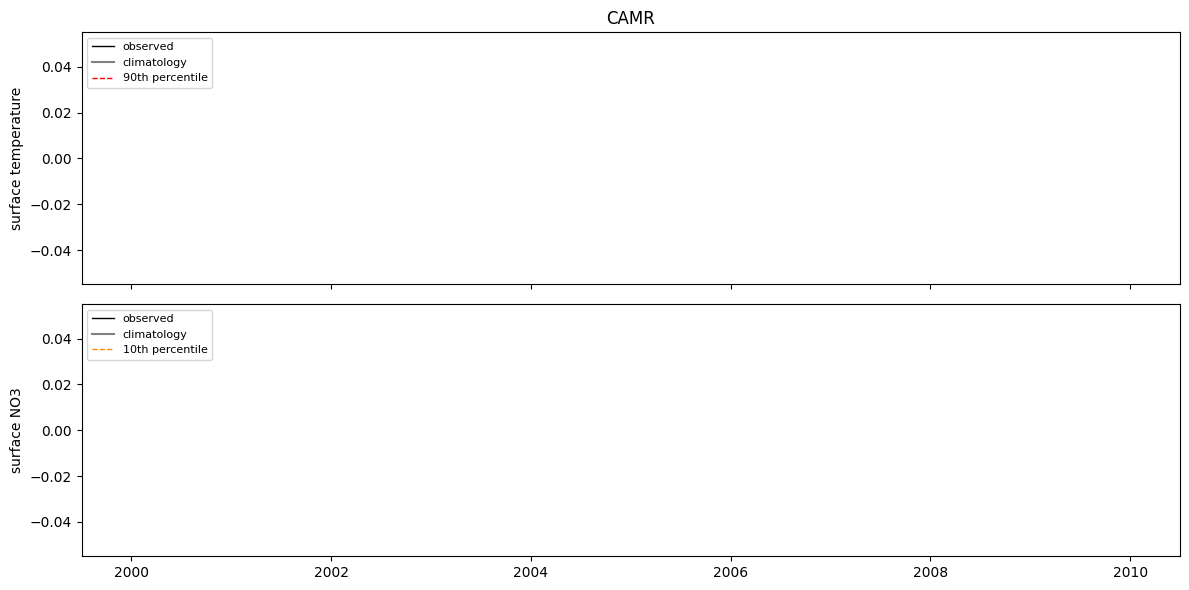

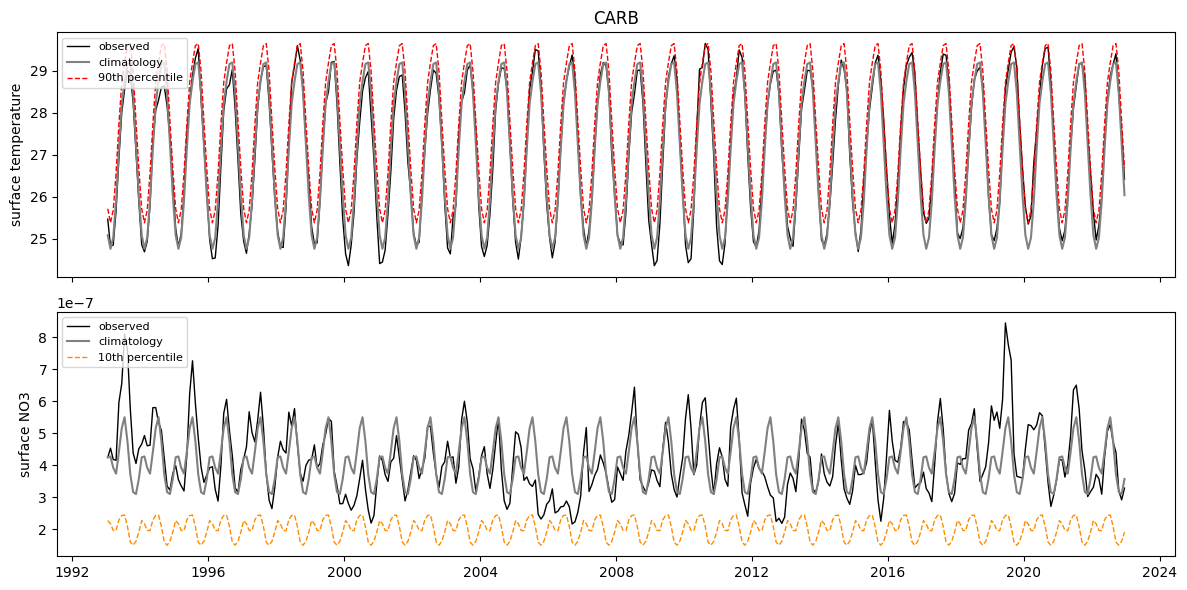

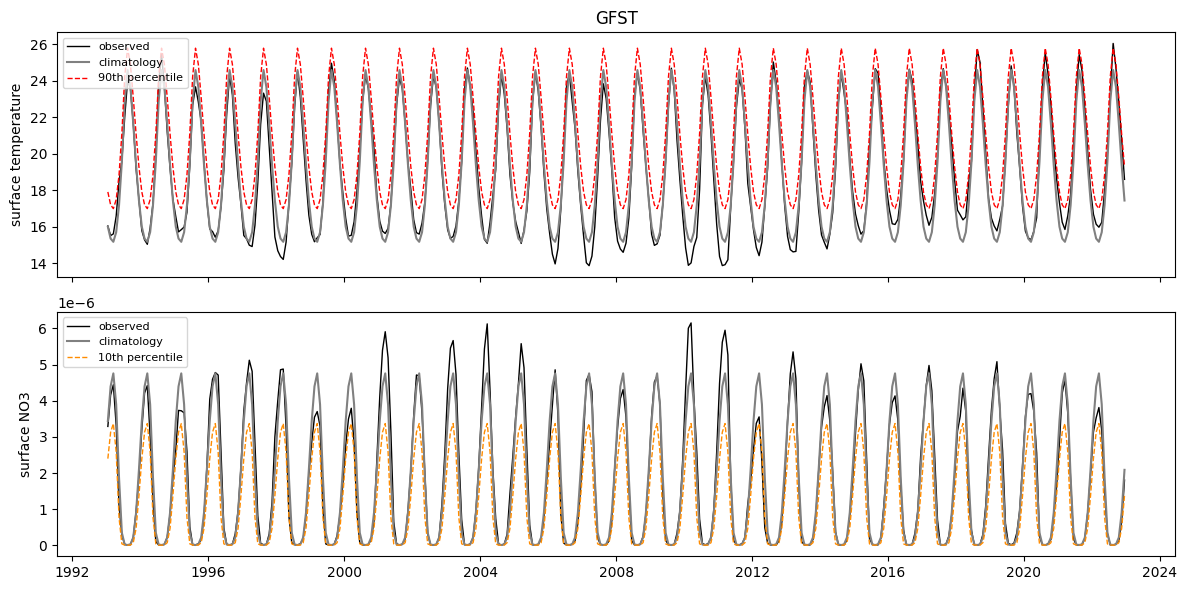

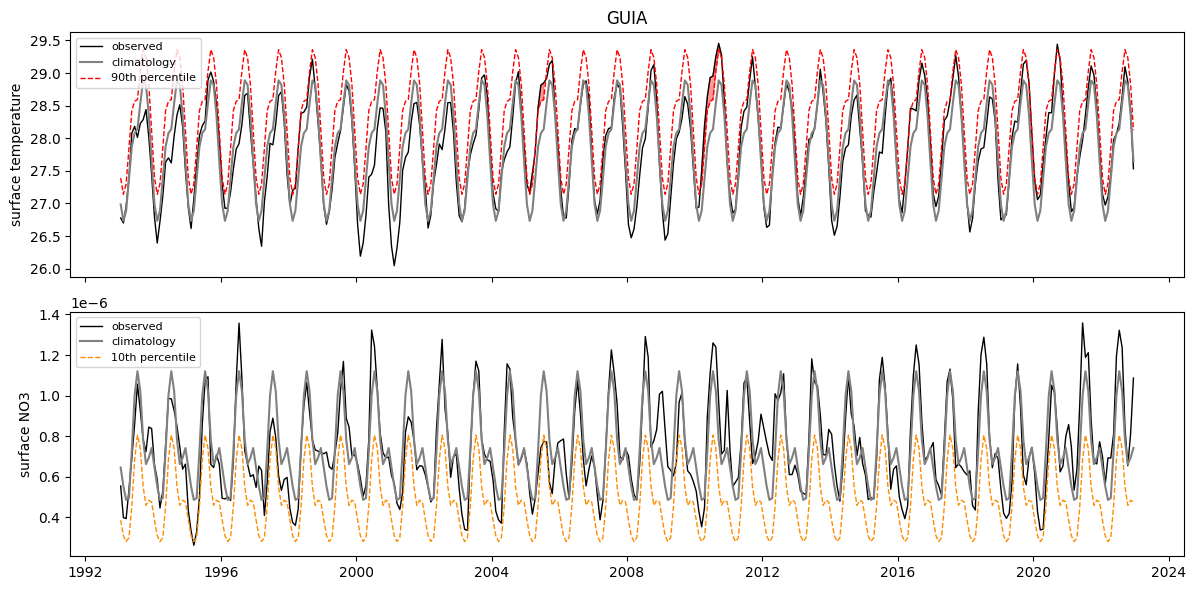

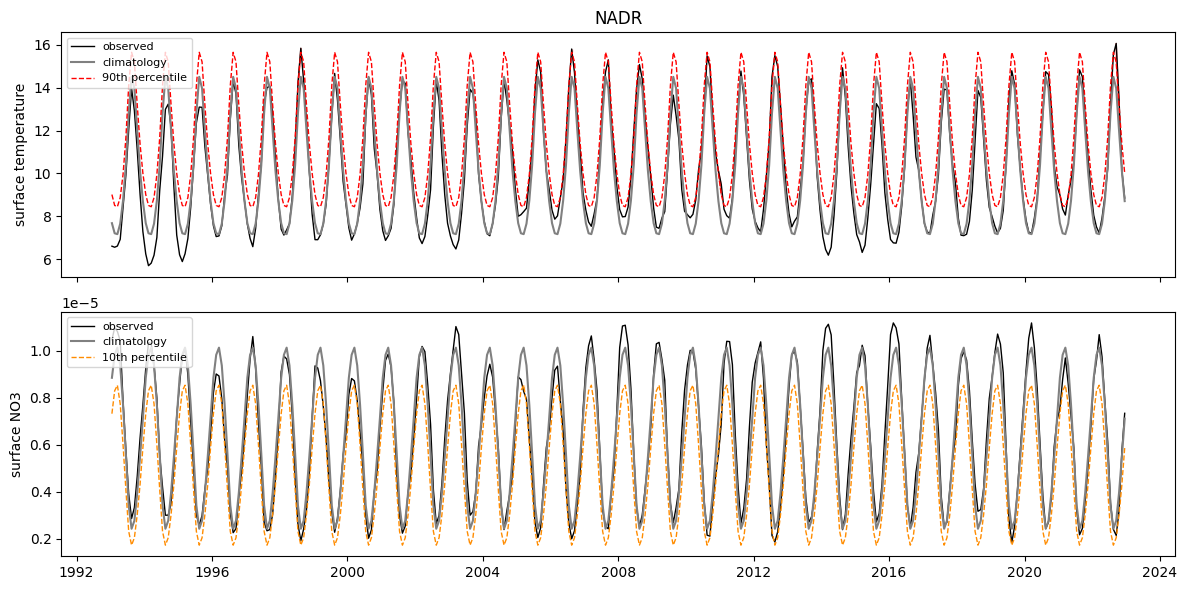

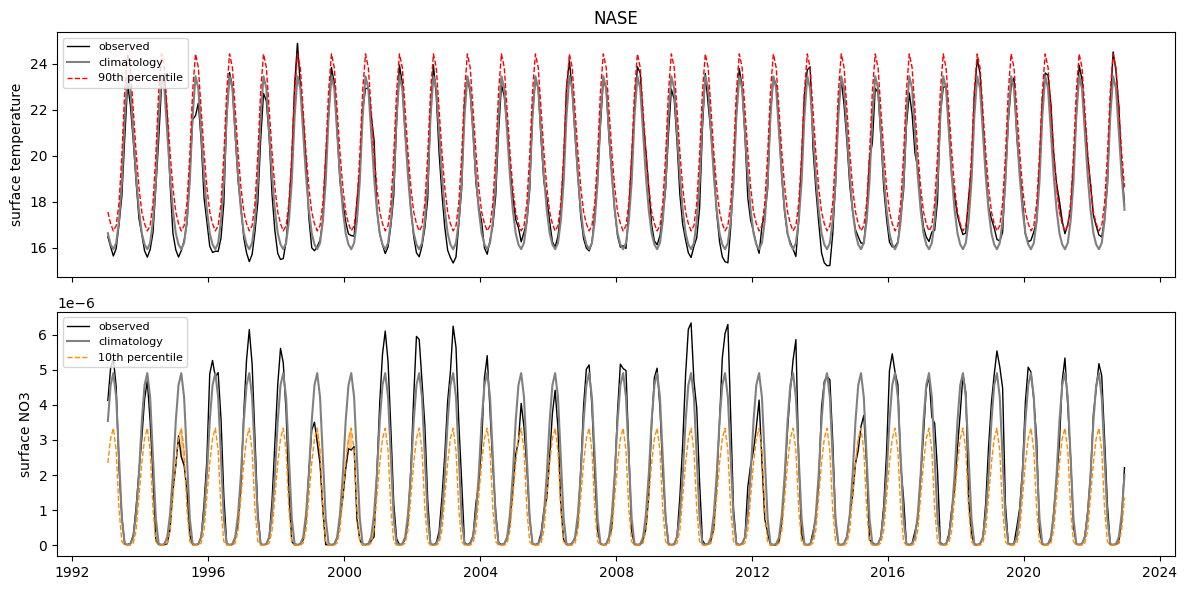

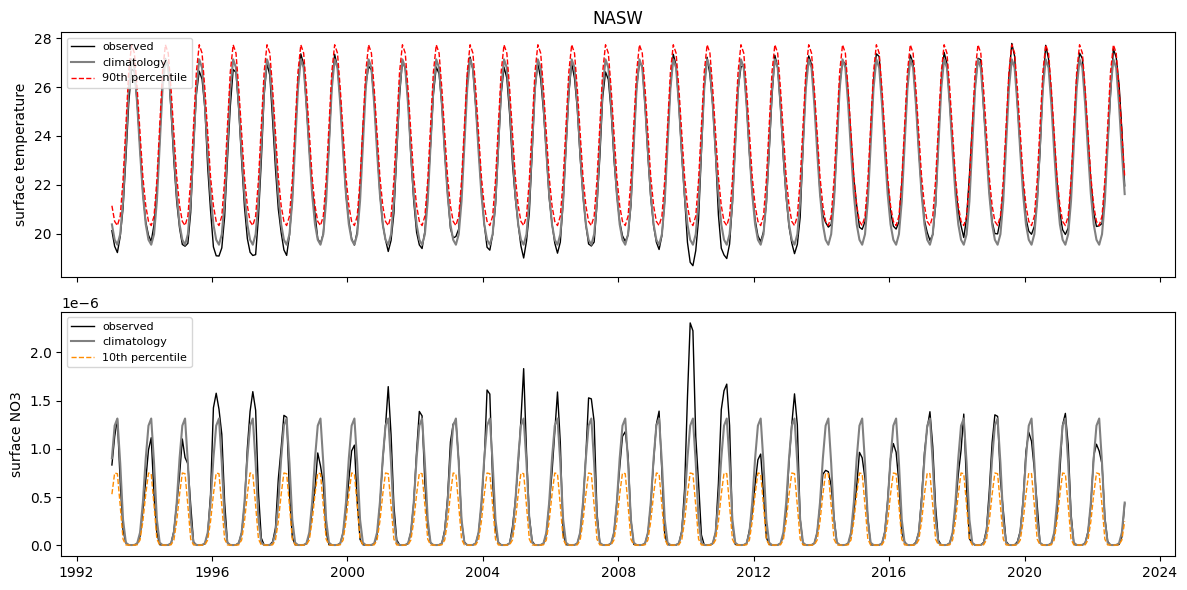

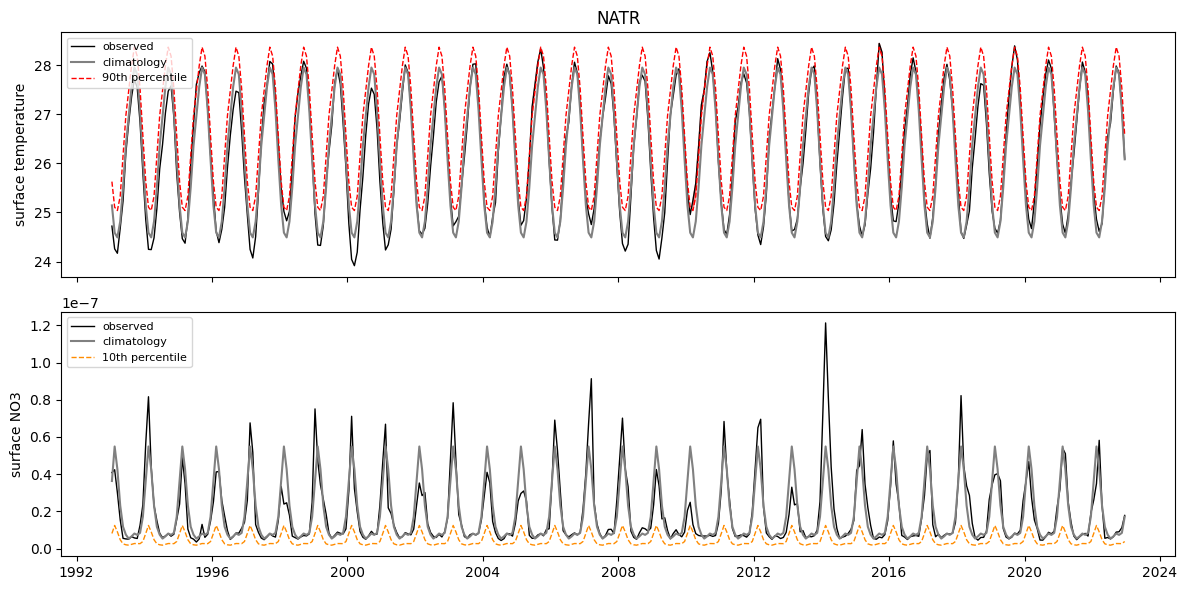

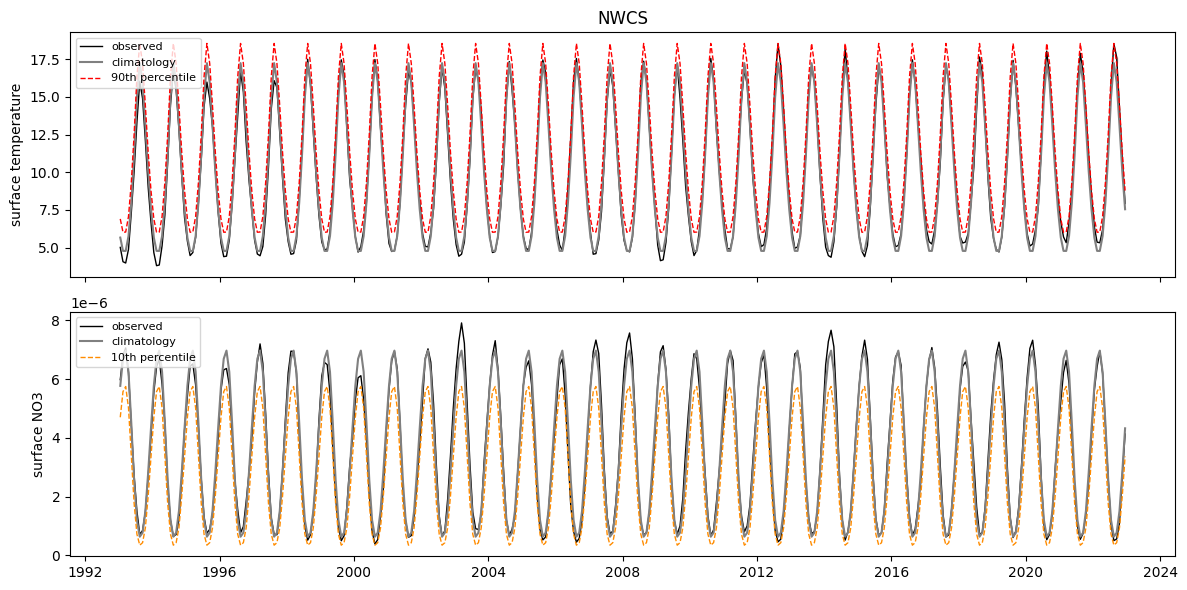

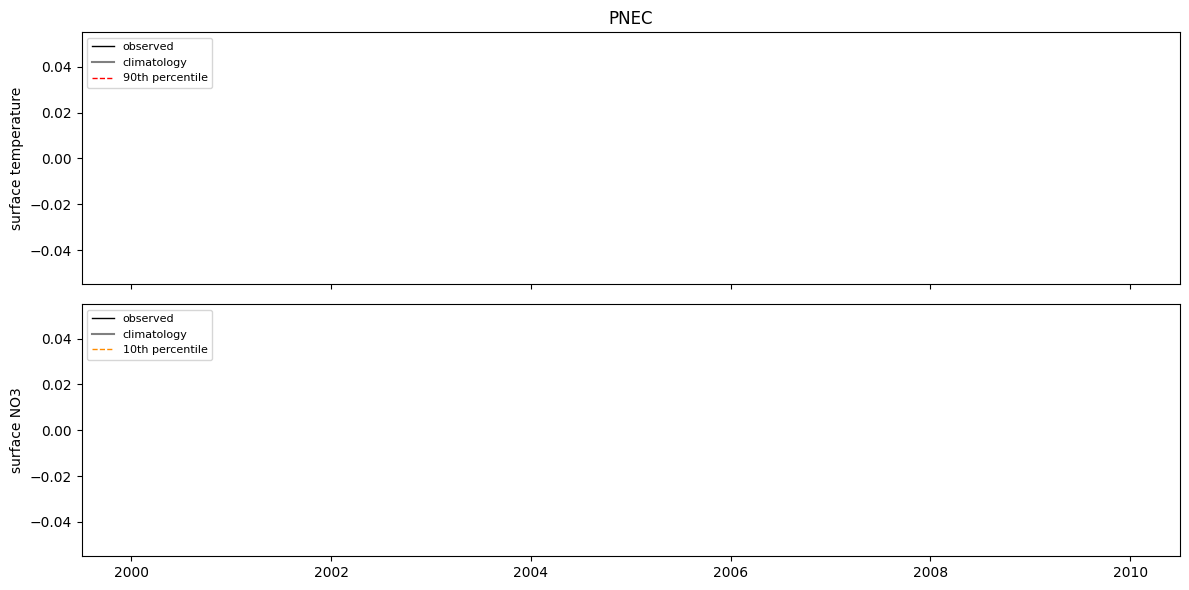

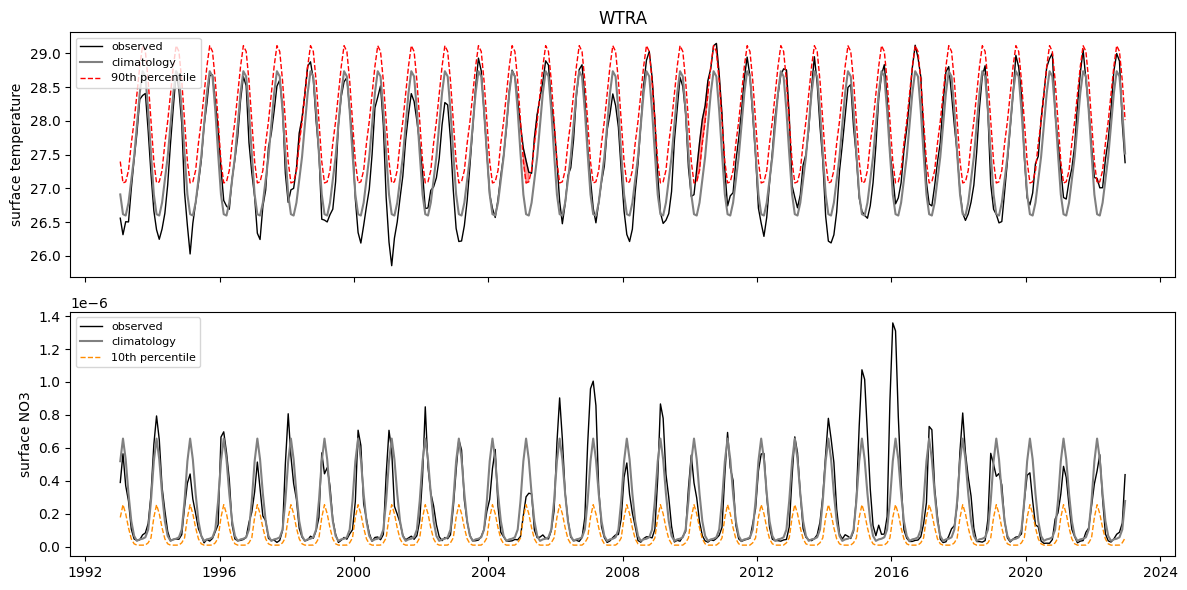

In [32]:
for code in prov.region.values:
    p = prov.sel(region=code)
    fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

    ax = axs[0]
    ax.plot(p.time, p.temp_ds, "k", lw=1, label="observed")
    ax.plot(p.time, p.tos_clim, color="grey", label="climatology")
    ax.plot(p.time, p.tos_per90, "r--", lw=1, label="90th percentile")
    ax.fill_between(p.time, p.tos_per90, p.temp_ds, where=p.temp_ds > p.tos_per90, color="r", alpha=0.4)
    ax.set_ylabel("surface temperature")
    ax.legend(loc="upper left", fontsize=8)
    ax.set_title(code)

    ax = axs[1]
    ax.plot(p.time, p.no3, "k", lw=1, label="observed")
    ax.plot(p.time, p.no3s_clim, color="grey", label="climatology")
    ax.plot(p.time, p.no3s_per10, "--", color="darkorange", lw=1, label="10th percentile")
    ax.fill_between(p.time, p.no3s_per10, p.no3, where=p.no3 < p.no3s_per10, color="darkorange", alpha=0.4)
    ax.set_ylabel("surface NO3")
    ax.legend(loc="upper left", fontsize=8)

    plt.tight_layout()
    plt.show()